# Notebook 1: Basic Flux Balance Analysis (FBA)

## Learning Objectives

By the end of this notebook, you will understand:
1. How to load a genome-scale metabolic model
2. What a metabolic model contains (reactions, metabolites, genes)
3. How to identify and set the biomass objective
4. How to run basic Flux Balance Analysis (FBA)
5. How to interpret FBA results
6. How to visualize metabolic fluxes

## What is Flux Balance Analysis?

FBA is a mathematical approach to analyze metabolic networks. It predicts the flow of metabolites ("fluxes") through the network under steady-state conditions. The key assumptions are:

- **Steady state**: Production equals consumption for each metabolite
- **Optimization**: The organism maximizes growth (or another objective)
- **Constraints**: Fluxes must obey reaction stoichiometry and bounds

---

## Step 1: Import Required Libraries

We'll use functions from our custom `src` package to keep the code clean and organized.

In [4]:
# Add the parent directory to the path so we can import from src/

from pathlib import Path
import sys

project_root = Path("..").resolve()
sys.path.insert(0, str(project_root))
# Import our custom functions
from src.model_io import load_model, get_model_summary
from src.fba_utils import find_biomass_reactions, set_biomass_reaction, run_fba, get_exchange_fluxes

# Import libraries for visualization
import pandas as pd
import matplotlib.pyplot as plt

# Make plots appear in the notebook
%matplotlib inline

print("✓ Libraries imported successfully!")

✓ Libraries imported successfully!


## Step 2: Load the Metabolic Model

Metabolic models are stored in SBML (Systems Biology Markup Language) format. This XML-based format contains:
- All reactions and their stoichiometry
- All metabolites and their compartments (cytoplasm, periplasm, extracellular)
- Gene-Protein-Reaction (GPR) associations
- Reaction bounds (constraints on flux values)

In [ ]:
from pathlib import Path

# Use the same project_root defined in Step 1
MODELS_DIR = project_root / "models"

MODEL_PATH = MODELS_DIR / "paeruginosa_MODEL1507180020.xml"  #The exact name of the file in the models folder

print("Model path:", MODEL_PATH)

model = load_model(str(MODEL_PATH))
model


Model path: I:\Bioinfo\karvarzi\New folder (2)\metabolic-modeling-education\metabolic-modeling-education\models\MODEL1507180020_url.xml
Loading model from: I:\Bioinfo\karvarzi\New folder (2)\metabolic-modeling-education\metabolic-modeling-education\models\MODEL1507180020_url.xml
✓ Model loaded: MODEL1507180020
  - Reactions:   1110
  - Metabolites: 879
  - Genes:       1054


Name,MODEL1507180020
Memory address,20b3c9e5df0
Number of metabolites,879
Number of reactions,1110
Number of genes,1054
Number of groups,0
Objective expression,1.0*PA_Biomass6_DM - 1.0*PA_Biomass6_DM_reverse_e4a05
Compartments,"cytosol, extracellular"


## Step 3: Explore the Model Structure

Let's look at what's inside the model.

In [6]:
# Get a summary of the model
summary = get_model_summary(model)

# Display it nicely
print("\nModel Summary:")
print("=" * 40)
for key, value in summary.items():
    print(f"{key:20s}: {value}")


Model Summary:
model_id            : MODEL1507180020
reactions           : 1110
metabolites         : 879
genes               : 1054
exchange_reactions  : 121
compartments        : 2


In [7]:
# Let's look at a few example reactions
print("\nExample reactions:")
print("=" * 80)

for i, rxn in enumerate(model.reactions[:5]):
    print(f"\n{i+1}. {rxn.id}: {rxn.name}")
    print(f"   Equation: {rxn.reaction}")
    print(f"   Bounds: {rxn.lower_bound} ≤ flux ≤ {rxn.upper_bound}")


Example reactions:

1. DM_26dap__M_c: meso-2,6-Diaminoheptanedioate demand
   Equation: 26dap__M_c --> 
   Bounds: 0.0 ≤ flux ≤ 0.0

2. DM_3pg_c: 3-Phospho-D-glycerate demand
   Equation: 3pg_c --> 
   Bounds: 0.0 ≤ flux ≤ 0.0

3. DM_4mhetz_c: 4-Methyl-5-(2-hydroxyethyl)-thiazole demand
   Equation: 4mhetz_c --> 
   Bounds: 0.0 ≤ flux ≤ 0.0

4. DM_EC_PREGRO: Biomass reaction for E coli precursor (core) growth
   Equation: 1.5 3pg_c + 3.7 accoa_c + 1.1 akg_c + 41.3 atp_c + 0.4 e4p_c + 0.1 f6p_c + 0.1 g3p_c + 0.2 g6p_c + 3.5 nad_c + 18.2 nadph_c + 1.8 oaa_c + 0.5 pep_c + 2.8 pyr_c + 0.9 r5p_c --> 41.3 adp_c + 3.7 coa_c + 9.0 h_c + 3.5 nadh_c + 18.2 nadp_c + 41.3 pi_c
   Bounds: 0.0 ≤ flux ≤ 0.0

5. DM_aacoa_c: Acetoacetyl-CoA demand
   Equation: aacoa_c --> 
   Bounds: 0.0 ≤ flux ≤ 0.0


In [8]:
# Let's look at a few example metabolites
print("\nExample metabolites:")
print("=" * 80)

for i, met in enumerate(model.metabolites[:5]):
    print(f"\n{i+1}. {met.id}: {met.name}")
    print(f"   Formula: {met.formula}")
    print(f"   Compartment: {met.compartment}")


Example metabolites:

1. 10fthf_c: 10-Formyltetrahydrofolate
   Formula: C20H21N7O7
   Compartment: c

2. 12d3k5m_c: 1,2-dihydroxy-3-keto-5-methylthiopentene
   Formula: 2-dihydroxy-3-keto-5-methylthiopentene
   Compartment: c

3. 12dag3p_c: 1,2-Diacyl-sn-glycerol 3-phosphate
   Formula: 2-Diacyl-sn-glycerol 3-phosphate
   Compartment: c

4. 12dag3p_PA_c: 1,2-Diacyl-sn-glycerol 3-phosphate
   Formula: None
   Compartment: c

5. 12dgr_c: 1,2-Diacylglycerol
   Formula: None
   Compartment: c


In [9]:
# Let's look at a few example genes
print("\nExample genes:")
print("=" * 80)

for i, gene in enumerate(list(model.genes)[:5]):
    print(f"\n{i+1}. {gene.id}: {gene.name}")
    print(f"   Catalyzes {len(gene.reactions)} reaction(s)")


Example genes:

1. PA0005: PA0005
   Catalyzes 1 reaction(s)

2. PA0006: PA0006
   Catalyzes 2 reaction(s)

3. PA0008: PA0008
   Catalyzes 1 reaction(s)

4. PA0009: PA0009
   Catalyzes 1 reaction(s)

5. PA0011: PA0011
   Catalyzes 1 reaction(s)


## Step 4: Find the Biomass Reaction

The **biomass reaction** represents cell growth. It consumes metabolic precursors (amino acids, nucleotides, lipids, etc.) to produce "biomass."

In FBA, we typically maximize the flux through the biomass reaction, which predicts the growth rate.

In [10]:
# Find biomass reactions
biomass_reactions = find_biomass_reactions(model)

Found 1 biomass reaction(s):
  - PA_Biomass6_DM: Pseudomonas biomass w/ heme


In [11]:
# Look at the first biomass reaction in detail
if biomass_reactions:
    biomass = biomass_reactions[0]
    print(f"\nBiomass reaction details:")
    print(f"ID: {biomass.id}")
    print(f"Name: {biomass.name}")
    print(f"\nReaction equation (first 200 characters):")
    print(biomass.reaction[:200] + "...")


Biomass reaction details:
ID: PA_Biomass6_DM
Name: Pseudomonas biomass w/ heme

Reaction equation (first 200 characters):
0.045754 5mthf_c + 0.007686 PA_core_lipidA_c + 4.5e-05 accoa_c + 0.446559 ala__L_c + 0.000915 amp_c + 0.25714 arg__L_c + 0.20955 asn__L_c + 0.20955 asp__L_c + 41.84827 atp_c + 9.6e-05 cdlp_PA_c + 5e-0...


## Step 5: Set the Biomass Objective

Now we'll tell the model to maximize growth by setting the biomass reaction as the objective function.

In [ ]:
# Set the biomass reaction as objective
# Replace "BIOMASS_PAO" with the actual ID from your model
BIOMASS_ID = "BIOMASS_PAO"  # Update this based on what you found above

model = set_biomass_reaction(model, BIOMASS_ID)

✓ Objective set to: PA_Biomass6_DM
  Reaction: Pseudomonas biomass w/ heme
  Direction: 0.0 ≤ flux ≤ 1000.0


## Step 6: Run Flux Balance Analysis

Now we can run FBA to predict the maximum growth rate and the metabolic flux distribution that achieves it.

**Note**: The model must have a valid growth medium (nutrients available) for growth to occur. Many models come with a default medium already configured.

In [13]:
# Run FBA
solution = run_fba(model)

✓ FBA successful!
  Objective value: 1.047929
  Status: optimal


## Step 7: Interpret the Results

The solution contains:
- **objective_value**: The predicted growth rate (1/hour)
- **fluxes**: The flux through each reaction (mmol/gDW/h)
- **status**: Whether optimization was successful

In [14]:
print(f"\nGrowth rate: {solution.objective_value:.4f} 1/h")
print(f"Optimization status: {solution.status}")

# The growth rate tells us how fast the organism can grow
# For example, 0.5 1/h means the cell mass doubles every ~1.4 hours
if solution.objective_value > 0:
    doubling_time = 0.693 / solution.objective_value  # ln(2) ≈ 0.693
    print(f"Estimated doubling time: {doubling_time:.2f} hours")


Growth rate: 1.0479 1/h
Optimization status: optimal
Estimated doubling time: 0.66 hours


## Step 8: Examine Exchange Fluxes

Exchange reactions represent uptake and secretion of metabolites.
- **Negative flux** = uptake (material entering cell)
- **Positive flux** = secretion (material leaving cell)

In [15]:
# Get exchange fluxes
exchange_fluxes = get_exchange_fluxes(solution, model)

# Convert to DataFrame for nice display
exchange_df = pd.DataFrame([
    {'Reaction ID': rxn_id, 
     'Flux (mmol/gDW/h)': flux,
     'Type': 'Uptake' if flux < 0 else 'Secretion'}
    for rxn_id, flux in exchange_fluxes.items()
])

# Sort by absolute flux (largest first)
exchange_df['abs_flux'] = exchange_df['Flux (mmol/gDW/h)'].abs()
exchange_df = exchange_df.sort_values('abs_flux', ascending=False)
exchange_df = exchange_df.drop('abs_flux', axis=1)

print("\nTop 10 exchange fluxes:")
print(exchange_df.head(10).to_string(index=False))


Top 10 exchange fluxes:
Reaction ID  Flux (mmol/gDW/h)      Type
   EX_h2o_e          41.339973 Secretion
   EX_co2_e          21.101940 Secretion
    EX_o2_e         -19.554860    Uptake
   EX_nh4_e         -10.229366    Uptake
   EX_glc_e         -10.000000    Uptake
     EX_h_e           8.784177 Secretion
    EX_pi_e          -0.875712    Uptake
   EX_so4_e          -0.223486    Uptake
 EX_gcald_e           0.047947 Secretion
   EX_fe2_e          -0.000001    Uptake


## Step 9: Visualize Flux Distribution

Let's create a simple visualization of the most active reactions.

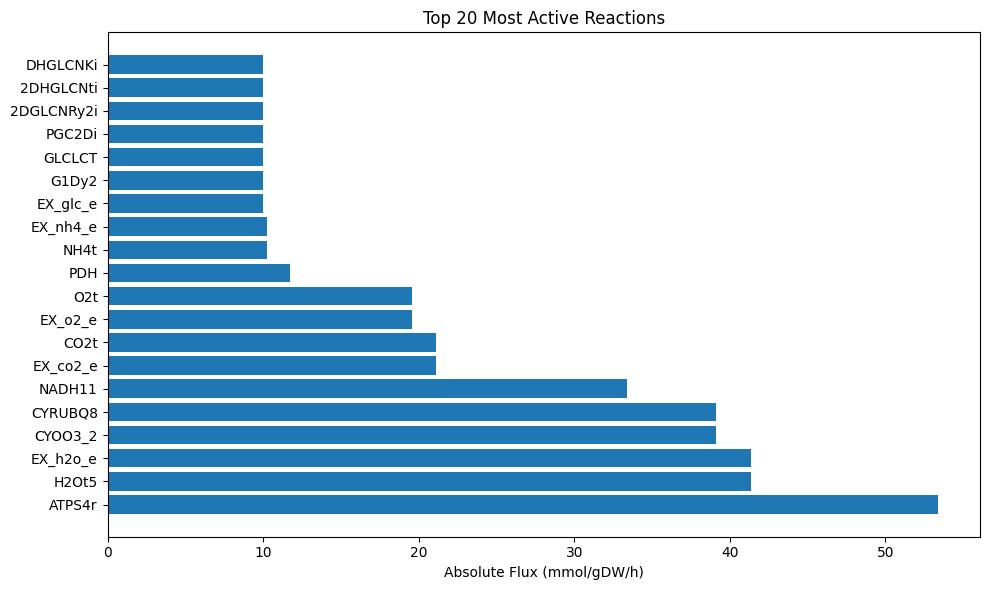

In [16]:
# Get all fluxes and find the most active reactions
all_fluxes = solution.fluxes.abs().sort_values(ascending=False)

# Plot the top 20 most active reactions
top_n = 20
top_fluxes = all_fluxes.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(range(len(top_fluxes)), top_fluxes.values)
plt.yticks(range(len(top_fluxes)), top_fluxes.index)
plt.xlabel('Absolute Flux (mmol/gDW/h)')
plt.title(f'Top {top_n} Most Active Reactions')
plt.tight_layout()
plt.show()

## Step 10: Visualize Uptake vs Secretion

Let's visualize what the cell is consuming vs. producing.

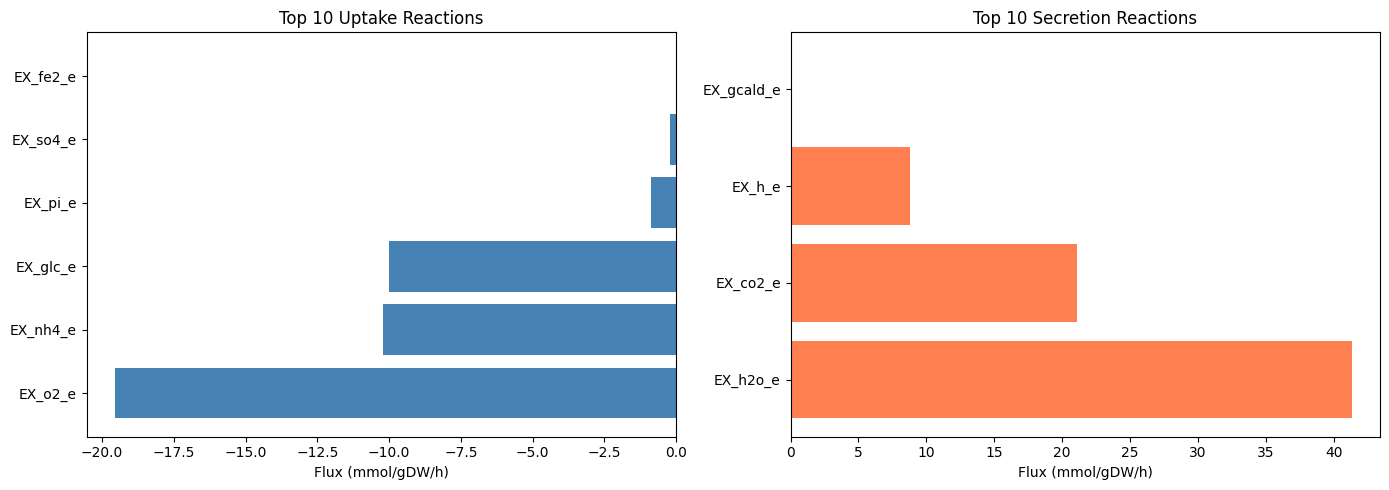

In [17]:
# Separate uptake and secretion
uptake = exchange_df[exchange_df['Type'] == 'Uptake'].copy()
secretion = exchange_df[exchange_df['Type'] == 'Secretion'].copy()

# Create side-by-side bar plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot uptake (take top 10)
if len(uptake) > 0:
    top_uptake = uptake.head(10)
    ax1.barh(range(len(top_uptake)), top_uptake['Flux (mmol/gDW/h)'].values, color='steelblue')
    ax1.set_yticks(range(len(top_uptake)))
    ax1.set_yticklabels(top_uptake['Reaction ID'].values)
    ax1.set_xlabel('Flux (mmol/gDW/h)')
    ax1.set_title('Top 10 Uptake Reactions')
    ax1.axvline(x=0, color='black', linewidth=0.5)

# Plot secretion (take top 10)
if len(secretion) > 0:
    top_secretion = secretion.head(10)
    ax2.barh(range(len(top_secretion)), top_secretion['Flux (mmol/gDW/h)'].values, color='coral')
    ax2.set_yticks(range(len(top_secretion)))
    ax2.set_yticklabels(top_secretion['Reaction ID'].values)
    ax2.set_xlabel('Flux (mmol/gDW/h)')
    ax2.set_title('Top 10 Secretion Reactions')
    ax2.axvline(x=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

## Summary

In this notebook, you learned:

1. ✓ How to load a genome-scale metabolic model
2. ✓ The basic components of a model (reactions, metabolites, genes)
3. ✓ How to identify and set the biomass objective function
4. ✓ How to run Flux Balance Analysis (FBA)
5. ✓ How to interpret growth rates and flux values
6. ✓ How to visualize metabolic activity

### Key Concepts:

- **FBA** predicts metabolic fluxes under steady-state conditions
- **Biomass reaction** represents cell growth
- **Growth rate** is typically measured in 1/h (per hour)
- **Exchange reactions** show what nutrients are consumed and what byproducts are secreted
- **Fluxes** are measured in mmol/gDW/h (millimoles per gram dry weight per hour)

### Next Steps:

In the next notebook, we'll explore **gene essentiality analysis** to predict which genes are required for growth.

---